# Legal Document Generator: an n-gram language model

An end-to-end, from-scratch n-gram model that learns from real contracts and writes contract-style text from a short prefix.

**Pipeline:** download data → clean → split by document → tokenise → build vocab from train only → count n-grams → tune on dev with perplexity → choose a prefix → generate → final test score → save.

| Concept | What this notebook uses |
|---|---|
| Learned parameters | N-gram probabilities (from train counts) and interpolation weights λ (from dev, with EM) |
| Hyperparameters | n, smoothing method, add-k's k, vocab cut-off, temperature, top-k |
| Evaluation metric | Perplexity: lower is better, roughly "how many words the model is choosing between at each step" |

**To scale up later:** change the numbers in the next cell and re-run everything. Generated text is a statistical imitation and is not usable as a legal document.

In [1]:
# ---- Config: everything you might want to change is here ----
SEED = 42

# Dataset size. Start small, raise these later.
TRAIN_DOCS = 1000
DEV_DOCS = 100
TEST_DOCS = 100

# Document filters
MIN_DOC_CHARS = 2_000
MAX_DOC_CHARS = 150_000

# Vocabulary: train words seen fewer times than this become <unk>
MIN_COUNT = 2

# Model search space (common values)
MAX_N = 5
ADD_K_GRID = [1.0, 0.1, 0.01, 0.001]
UNIGRAM_ALPHA = 1.0   # keeps every vocab word's probability above zero
EM_ITERS = 50
# Among models within this fraction of the best dev perplexity, take the smallest n
SELECTION_TOLERANCE = 0.01

# Learning curve: train sizes to compare
LEARNING_CURVE_SIZES = [25, 50, 100, 150, 300, 600, 1000]

# Generation hyperparameters (not tuned by perplexity, they control style)
TEMPERATURE = 0.8
TOP_K = 30
MAX_GEN_TOKENS = 120
MAX_SENTENCE_OVERRUN = 60   # extra tokens allowed so the last sentence can finish
MAX_QUOTE_TOKENS = 6        # defined terms are short, so a quote must close within this
MIN_SENTENCE_TOKENS = 5     # stops headings like "section 3." counting as a sentence

# Prefix research
OPENING_SENTS = 5   # how near the top a phrase must be to count as an opening
MIN_PREFIX_ENTROPY = 1.0   # bits; below this nearly every output continues the same way
MIN_PREFIX_STARTS = 5      # sentences in train that begin with the prefix
CANDIDATE_PREFIXES = [
    "whereas , the", "this agreement", "this agreement is made", "this agreement is entered into",
    "this agreement is made and entered into", "this amendment", "whereas",
    "now , therefore", "in witness whereof", "the parties", "introduction",
]

In [2]:
import hashlib
import json
import math
import pickle
import random
import re
import time
import urllib.error
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
DATA_PATH = ROOT / "data" / "raw_contracts.jsonl"
MODEL_PATH = ROOT / "models" / "ngram_model.pkl"
REPORT_DIR = ROOT / "reports"
for folder in (DATA_PATH.parent, MODEL_PATH.parent, REPORT_DIR):
    folder.mkdir(exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.max_colwidth", 120)

# Chart styling
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e0"
SERIES_1, SERIES_2 = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "lines.linewidth": 2, "lines.markersize": 8,
    "axes.titlelocation": "left", "axes.titleweight": "bold",
})

## 1. Data

**Source:** [`albertvillanova/legal_contracts`](https://huggingface.co/datasets/albertvillanova/legal_contracts) on Hugging Face: 106,000 contracts, mostly exhibits attached to SEC filings.

The full set is about 5 GB, so this downloads small pages from random positions in the dataset. That avoids taking everything from one time period. Downloads are cached, so re-runs work offline, and raising the sizes only fetches the extra pages.

In [3]:
API = "https://datasets-server.huggingface.co/rows?dataset=albertvillanova/legal_contracts&config=default&split=train"
DATASET_ROWS = 106_000
PAGE_SIZE = 20
# Some raw rows don't survive filtering and de-duplication, so fetch extra
USABLE_RATE = 0.6   # slightly below the share that survives cleaning, as a safety margin
POOL_ROWS = int(max(TRAIN_DOCS / 0.7, DEV_DOCS / 0.15, TEST_DOCS / 0.15) / USABLE_RATE)


REQUEST_PAUSE = 1.0   # seconds between pages, to stay within the API's rate limit


def fetch_page(offset, retries=8):
    url = f"{API}&offset={offset}&length={PAGE_SIZE}"
    for attempt in range(retries):
        try:
            with urllib.request.urlopen(url, timeout=60) as response:
                return [row["row"]["text"] for row in json.load(response)["rows"]]
        except urllib.error.HTTPError as error:
            if attempt == retries - 1 or (error.code != 429 and error.code < 500):
                raise
            # Rate limited: wait as long as the server asks, or back off up to 5 minutes
            retry_after = error.headers.get("Retry-After", "")
            wait = int(retry_after) if retry_after.isdigit() else min(300, 30 * 2 ** attempt)
            print(f"HTTP {error.code} at offset {offset}; waiting {wait}s")
            time.sleep(wait)
        except (urllib.error.URLError, TimeoutError):
            if attempt == retries - 1:
                raise
            time.sleep(2 ** attempt)


def load_raw_docs(pool_rows):
    cached = {}
    if DATA_PATH.exists():
        with DATA_PATH.open() as f:
            for line in f:
                page = json.loads(line)
                cached[page["offset"]] = page["texts"]

    # Shuffled once, so a bigger pool extends the smaller one instead of replacing it
    offsets = list(range(0, DATASET_ROWS - PAGE_SIZE, 100))
    random.Random(SEED).shuffle(offsets)
    wanted = offsets[: math.ceil(pool_rows / PAGE_SIZE)]

    with DATA_PATH.open("a") as f:
        for offset in wanted:
            if offset not in cached:
                cached[offset] = fetch_page(offset)
                f.write(json.dumps({"offset": offset, "texts": cached[offset]}) + "\n")
                f.flush()  # keep progress if the download stops part way
                time.sleep(REQUEST_PAUSE)
    return [text for offset in wanted for text in cached[offset]]


raw_docs = load_raw_docs(POOL_ROWS)
print(f"Raw documents: {len(raw_docs):,}")
print(f"Example opening:\n{raw_docs[0][:300]!r}")

Raw documents: 2,380
Example opening:
'EXHIBIT 10-A\n\nAMENDMENT TO THE\n\nCOLGATE-PALMOLIVE COMPANY\n\n2005 EMPLOYEE STOCK OPTION PLAN\n\nAMENDMENT, dated as of September\xa07, 2006 (this “Amendment”), to the\nColgate-Palmolive Company (the “Company”) 2005 Employee Stock Option Plan (the\n“Plan”).\n\nWHEREAS, the Plan currently provides that the exerc'


## 2. Cleaning and splitting

Filings carry a lot of noise, so this step:

- Normalises curly quotes and non-breaking spaces.
- Removes `Exhibit 10.x` headers, `Execution Copy` stamps, separators and page numbers.
- Keeps only documents that mention "agreement" in their opening text and have a sensible length.
- Removes duplicates, so the same contract can't appear in both train and dev.

The split is **by document**. Splitting by sentence would put parts of one contract in both train and dev, which would make perplexity look better than it really is.

Each document's split comes from a hash of its text (70% train, 15% dev, 15% test), so it never changes. Raising `TRAIN_DOCS` adds training documents while dev and test stay the same, which keeps runs of different sizes comparable.

In [4]:
CHAR_MAP = str.maketrans({
    " ": " ", "‘": "'", "’": "'", "“": '"', "”": '"',
    "–": "-", "—": "-", "\t": " ",
})
# Fill-in blanks become a placeholder word that falls out of the vocabulary as <unk>.
# Deleting them instead would invent word pairs like "the ," that no contract contains.
BLANK = re.compile(r"_{2,}")
SEPARATOR = re.compile(r"[-=*~.]{3,}")
# Only applied to the top of a document, where "Exhibit A" is a header and not a reference
HEADER = re.compile(r"^(?:exhibit\s+[\w.()\-]+|execution\s+(?:copy|version)|quicklinks.*)\s*", re.IGNORECASE)
HEADER_PARAGRAPHS = 5
PAGE_NUMBER = re.compile(r"^(?:page\s+)?\d+(?:\s+of\s+\d+)?$", re.IGNORECASE)


def clean_paragraphs(text):
    text = BLANK.sub(" blankfield ", text.translate(CHAR_MAP))
    text = SEPARATOR.sub(" ", text)
    paragraphs = []
    for block in re.split(r"\n\s*\n", text):
        paragraph = " ".join(block.split())
        # Headers can stack ("Exhibit 10.1 Execution Copy ..."), so strip repeatedly
        while len(paragraphs) < HEADER_PARAGRAPHS and (stripped := HEADER.sub("", paragraph)) != paragraph:
            paragraph = stripped
        if re.search(r"[A-Za-z]{2}", paragraph) and not PAGE_NUMBER.match(paragraph):
            paragraphs.append(paragraph)
    return paragraphs


def is_usable(text):
    return (MIN_DOC_CHARS <= len(text) <= MAX_DOC_CHARS
            and "agreement" in text[:1500].lower())


def split_of(fingerprint):
    bucket = int(fingerprint[:8], 16) % 100
    return "test" if bucket < 15 else "dev" if bucket < 30 else "train"


def prepare_documents(raw):
    splits = {"train": [], "dev": [], "test": []}
    seen = set()
    dropped = Counter()
    for text in raw:
        if not is_usable(text):
            dropped["filtered"] += 1
            continue
        paragraphs = clean_paragraphs(text)
        fingerprint = hashlib.md5(" ".join(paragraphs)[:1000].lower().encode()).hexdigest()
        if fingerprint in seen:
            dropped["duplicate"] += 1
            continue
        seen.add(fingerprint)
        splits[split_of(fingerprint)].append(paragraphs)
    return splits, dropped


splits, dropped = prepare_documents(raw_docs)
print(f"Usable: {sum(map(len, splits.values())):,} | dropped: {dict(dropped)}")

for name, wanted in [("train", TRAIN_DOCS), ("dev", DEV_DOCS), ("test", TEST_DOCS)]:
    if len(splits[name]) < wanted:
        raise ValueError(f"Need {wanted} {name} documents, have {len(splits[name])}. Lower USABLE_RATE.")

train_docs = splits["train"][:TRAIN_DOCS]
dev_docs = splits["dev"][:DEV_DOCS]
test_docs = splits["test"][:TEST_DOCS]
print(f"Split: train={len(train_docs)}, dev={len(dev_docs)}, test={len(test_docs)}")

Usable: 1,566 | dropped: {'filtered': 814}
Split: train=1000, dev=100, test=100


## 3. Tokenisation and vocabulary

The tokeniser lowercases text and keeps numbers like `1,000.50` and words like `non-compete` whole. Lowercasing reduces sparsity because `AGREEMENT` and `Agreement` share counts.

Sentences get `<s>` padding and a `</s>` ending, so the model can learn how sentences start and stop. Legal abbreviations like `Inc.` and `No.` don't end a sentence.

**The vocabulary comes from train only.** Rare train words become `<unk>`, which teaches the model how to handle unseen words. Dev and test words outside the vocabulary also become `<unk>`.

In [5]:
BOS, EOS, UNK = "<s>", "</s>", "<unk>"
TOKEN = re.compile(r"\d+(?:[.,]\d+)*(?![a-z\d])|[a-z\d]+(?:[-'][a-z\d]+)*|[^\s\w]")
SENTENCE_END = re.compile(r"[.?!][\"')]*\s+(?=[\"'(]?[A-Z])")
ABBREVIATIONS = {
    "no.", "nos.", "inc.", "corp.", "co.", "ltd.", "llc.", "l.l.c.", "l.p.", "mr.", "mrs.", "ms.", "dr.",
    "sec.", "art.", "st.", "ave.", "u.s.", "e.g.", "i.e.", "etc.", "vs.", "v.", "jan.", "feb.", "mar.",
    "apr.", "jun.", "jul.", "aug.", "sept.", "sep.", "oct.", "nov.", "dec.",
}


def split_sentences(paragraph):
    sentences, start = [], 0
    for match in SENTENCE_END.finditer(paragraph):
        last_word = paragraph[start:match.start() + 1].split()[-1].lower().lstrip("(\"'")
        # Skip abbreviations and list markers like "1." or "A."
        if last_word in ABBREVIATIONS or re.fullmatch(r"[a-z0-9]{1,2}\.", last_word):
            continue
        sentences.append(paragraph[start:match.end()].strip())
        start = match.end()
    sentences.append(paragraph[start:].strip())
    return [s for s in sentences if s]


def tokenize(text):
    return TOKEN.findall(text.lower())


def tokenize_doc(paragraphs):
    sentences = (tokenize(s) for p in paragraphs for s in split_sentences(p))
    return [s for s in sentences if len(s) >= 2]


train_tok = [tokenize_doc(d) for d in train_docs]
dev_tok = [tokenize_doc(d) for d in dev_docs]
test_tok = [tokenize_doc(d) for d in test_docs]


def flatten(docs):
    return [sentence for doc in docs for sentence in doc]


def build_vocab(sentences, min_count):
    counts = Counter(word for sentence in sentences for word in sentence)
    words = {word for word, count in counts.items() if count >= min_count} - {"blankfield"}
    return words | {UNK, EOS}, counts


def apply_vocab(sentences, vocab):
    return [[word if word in vocab else UNK for word in sentence] for sentence in sentences]


def oov_rate(sentences, vocab):
    words = [word for sentence in sentences for word in sentence]
    return sum(word not in vocab for word in words) / len(words)


vocab, train_counts = build_vocab(flatten(train_tok), MIN_COUNT)
V = len(vocab)

summary = pd.DataFrame([
    {"split": name, "docs": len(docs), "sentences": len(flatten(docs)),
     "tokens": sum(map(len, flatten(docs))), "OOV rate": f"{oov_rate(flatten(docs), vocab):.2%}"}
    for name, docs in [("train", train_tok), ("dev", dev_tok), ("test", test_tok)]
])
print(f"Vocabulary size (train only, min_count={MIN_COUNT}): {V:,}")
display(summary)
print("Most common train words:", [word for word, _ in train_counts.most_common(15)])
print("\nExample sentence:", train_tok[0][min(3, len(train_tok[0]) - 1)][:30])

Vocabulary size (train only, min_count=2): 22,618


,split,docs,sentences,tokens,OOV rate
0,train,1000,160438,5512528,0.26%
1,dev,100,15551,557925,1.29%
2,test,100,15807,535712,1.44%


Most common train words: ['the', ',', 'of', 'to', 'and', '.', 'or', ')', '(', 'in', 'any', 'a', 'shall', 'by', '"']

Example sentence: ['this', 'will', 'confirm', 'our', 'understanding', 'regarding', 'certain', 'amendments', 'to', 'your', 'employment', 'agreement', 'with', 'the', 'company', 'dated', 'november', '1', ',', '2002', '(', 'your', '"', 'agreement', '"', ')', '.']


## 4. The model

An n-gram model predicts each word from the previous n−1 words. Its parameters are simple counts:

$$P_{MLE}(w \mid \text{context}) = \frac{\text{count}(\text{context}, w)}{\text{count}(\text{context})}$$

Plain counts give unseen n-grams a probability of zero, which makes perplexity infinite. Three common smoothing methods fix that:

- **Add-k:** adds a small k to every count. $P = \frac{c + k}{\text{total} + kV}$
- **Linear interpolation:** blends every order from unigram to n-gram. $P = \sum_i \lambda_i P_i$. The weights λ are learned on dev with EM, and they're the same for every context.
- **Witten-Bell:** also blends orders, but decides per context. $P_n = \frac{c + T \cdot P_{n-1}}{\text{total} + T}$, where T is the number of different words seen after this context. A context seen many times with few different followers is trusted; otherwise it leans on the shorter context. There's nothing to tune.

**Perplexity** is the exponential of the average negative log probability per token:

$$\text{perplexity} = \exp\left(-\frac{1}{N}\sum_{i} \ln P(w_i \mid \text{context}_i)\right)$$

It counts `</s>` as a token but not `<s>`, because the model never has to predict the padding.

In [6]:
class NGramModel:
    """Counts for every order from 1 to max_n, stored as {order: {context: {word: count}}}."""

    def __init__(self, vocab, max_n):
        self.vocab = vocab
        self.V = len(vocab)
        self.max_n = max_n
        self.tables = {order: {} for order in range(1, max_n + 1)}
        self.totals = {order: {} for order in range(1, max_n + 1)}
        # Defaults used by generation, set after tuning
        self.n = max_n
        self.method = "interpolation"
        self.lambdas = None
        self.k = None

    def fit(self, sentences):
        for sentence in apply_vocab(sentences, self.vocab):
            sequence = [BOS] * (self.max_n - 1) + sentence + [EOS]
            for i in range(self.max_n - 1, len(sequence)):
                word = sequence[i]
                for order in range(1, self.max_n + 1):
                    context = tuple(sequence[i - order + 1:i])
                    next_words = self.tables[order].setdefault(context, {})
                    next_words[word] = next_words.get(word, 0) + 1
                    self.totals[order][context] = self.totals[order].get(context, 0) + 1
        return self

    def count(self, order, context, word):
        return self.tables[order].get(context, {}).get(word, 0)

    def total(self, order, context):
        return self.totals[order].get(context, 0)

    def word_prob(self, word, history):
        """Probability of word given a history (list of tokens), using the tuned settings."""
        contexts = [tuple(history[-(order - 1):]) if order > 1 else () for order in range(1, self.n + 1)]
        if self.method == "add_k":
            order, context = self.n, contexts[-1]
            return (self.count(order, context, word) + self.k) / (self.total(order, context) + self.k * self.V)
        if self.method == "witten_bell":
            probability = (self.count(1, (), word) + UNIGRAM_ALPHA) / (self.total(1, ()) + UNIGRAM_ALPHA * self.V)
            for order, context in enumerate(contexts[1:], start=2):
                types = len(self.tables[order].get(context, {}))
                if types:
                    probability = (self.count(order, context, word) + types * probability) / (self.total(order, context) + types)
            return probability
        probability = 0.0
        for order, (context, weight) in enumerate(zip(contexts, self.lambdas), start=1):
            count, total = self.count(order, context, word), self.total(order, context)
            if order == 1:
                probability += weight * (count + UNIGRAM_ALPHA) / (total + UNIGRAM_ALPHA * self.V)
            elif total:
                probability += weight * count / total
        return probability


def count_matrices(model, sentences):
    """For each token to predict: its n-gram count, context total and context types at every order."""
    n = model.max_n
    counts, totals, types = [], [], []
    for sentence in apply_vocab(sentences, model.vocab):
        sequence = [BOS] * (n - 1) + sentence + [EOS]
        for i in range(n - 1, len(sequence)):
            word = sequence[i]
            row_counts, row_totals, row_types = [], [], []
            for order in range(1, n + 1):
                context = tuple(sequence[i - order + 1:i])
                row_counts.append(model.count(order, context, word))
                row_totals.append(model.total(order, context))
                row_types.append(len(model.tables[order].get(context, {})))
            counts.append(row_counts)
            totals.append(row_totals)
            types.append(row_types)
    return tuple(np.array(m, dtype=np.float64) for m in (counts, totals, types))


def perplexity(probabilities):
    return float(np.exp(-np.mean(np.log(probabilities))))


def add_k_probs(C, T, n, k, V):
    return (C[:, n - 1] + k) / (T[:, n - 1] + k * V)


def order_probs(C, T, V):
    """Unsmoothed probability at each order, except the unigram, which is add-alpha smoothed."""
    P = np.divide(C, T, out=np.zeros_like(C), where=T > 0)
    P[:, 0] = (C[:, 0] + UNIGRAM_ALPHA) / (T[:, 0] + UNIGRAM_ALPHA * V)
    return P


def witten_bell_probs(C, T, Y, n, V):
    probs = (C[:, 0] + UNIGRAM_ALPHA) / (T[:, 0] + UNIGRAM_ALPHA * V)
    for order in range(1, n):
        seen = Y[:, order] > 0
        probs = np.where(seen, (C[:, order] + Y[:, order] * probs) / np.where(seen, T[:, order] + Y[:, order], 1), probs)
    return probs


def em_lambdas(P, iterations=EM_ITERS):
    """Learn interpolation weights by EM: each order earns credit for how well it predicts."""
    lambdas = np.full(P.shape[1], 1 / P.shape[1])
    for _ in range(iterations):
        weighted = P * lambdas
        lambdas = (weighted / weighted.sum(axis=1, keepdims=True)).mean(axis=0)
    return lambdas


start = time.time()
model = NGramModel(vocab, MAX_N).fit(flatten(train_tok))
print(f"Trained in {time.time() - start:.1f}s")
print(pd.Series({f"{order}-gram": len(model.tables[order]) for order in model.tables}, name="distinct contexts").to_string())

context = ("this",)
top_next = sorted(model.tables[2].get(context, {}).items(), key=lambda item: -item[1])[:8]
print("\nLearned parameters for P(word | 'this'):")
for word, count in top_next:
    print(f"  {word:<14}{count / model.total(2, context):.3f}")

Trained in 17.3s
1-gram          1
2-gram      22618
3-gram     402134
4-gram    1357749
5-gram    2367937

Learned parameters for P(word | 'this'):
  agreement     0.584
  section       0.081
  amendment     0.038
  option        0.019
  paragraph     0.016
  lease         0.013
  letter        0.011
  note          0.010


## 5. Tuning on the dev set

This compares every n from 1 to 5 under all three smoothing methods. Only train counts and dev perplexity are used, and the test set stays untouched.

**Selection rule:** several setups usually score almost the same, so this takes the smallest n within 1% of the best score. A smaller n means a smaller model and less risk of copying, for no real loss in score.

The vocabulary is fixed throughout, because perplexity isn't comparable across different vocabularies: a smaller vocab turns more words into `<unk>`, which lowers the score without making the model better.

In [7]:
dev_sentences = flatten(dev_tok)
C_dev, T_dev, Y_dev = count_matrices(model, dev_sentences)
P_dev = order_probs(C_dev, T_dev, V)

results = []
for n in range(1, MAX_N + 1):
    for k in ADD_K_GRID:
        results.append({"method": "add_k", "n": n, "k": k, "lambdas": None,
                        "dev_perplexity": perplexity(add_k_probs(C_dev, T_dev, n, k, V))})
    lambdas = em_lambdas(P_dev[:, :n])
    results.append({"method": "interpolation", "n": n, "k": None, "lambdas": lambdas,
                    "dev_perplexity": perplexity(P_dev[:, :n] @ lambdas)})
    results.append({"method": "witten_bell", "n": n, "k": None, "lambdas": None,
                    "dev_perplexity": perplexity(witten_bell_probs(C_dev, T_dev, Y_dev, n, V))})
results = pd.DataFrame(results)

print(f"Uniform-guess baseline (every word equally likely): {V:,}")
display(results.pivot_table(index="n", columns="k", values="dev_perplexity").round(1)
        .rename(columns=lambda k: f"add-k={k}")
        .join(results[results.method == "interpolation"].set_index("n").dev_perplexity.round(1).rename("interpolation"))
        .join(results[results.method == "witten_bell"].set_index("n").dev_perplexity.round(1).rename("witten_bell")))

lowest = results.dev_perplexity.min()
close = results[results.dev_perplexity <= lowest * (1 + SELECTION_TOLERANCE)]
best = close.sort_values(["n", "dev_perplexity"]).iloc[0]
print(f"Lowest dev perplexity: {lowest:.1f}. Within {SELECTION_TOLERANCE:.0%} of it:")
print(close[["method", "n", "dev_perplexity"]].round(2).to_string(index=False))
print(f"Chosen: {best.method}, n={best.n}, dev perplexity={best.dev_perplexity:.1f}")
if best.method == "interpolation":
    print("Learned lambdas:", {f"{i + 1}-gram": round(float(w), 3) for i, w in enumerate(best.lambdas)})
elif best.method == "add_k":
    print(f"Best k: {best.k}")

model.n, model.method = int(best.n), best.method
model.lambdas, model.k = best.lambdas, best.k

Uniform-guess baseline (every word equally likely): 22,618


,add-k=0.001,add-k=0.01,add-k=0.1,add-k=1.0,interpolation,witten_bell
n,,,,,,
1,421.5,421.5,421.5,421.8,421.8,421.8
2,89.1,89.9,119.9,256.6,79.1,76.9
3,99.8,136.9,331.8,1236.6,44.5,41.9
4,302.6,515.3,1324.3,3962.9,39.7,38.4
5,903.3,1527.1,3291.9,7370.8,39.1,40.1


Lowest dev perplexity: 38.4. Within 1% of it:
     method  n  dev_perplexity
witten_bell  4           38.39
Chosen: witten_bell, n=4, dev perplexity=38.4


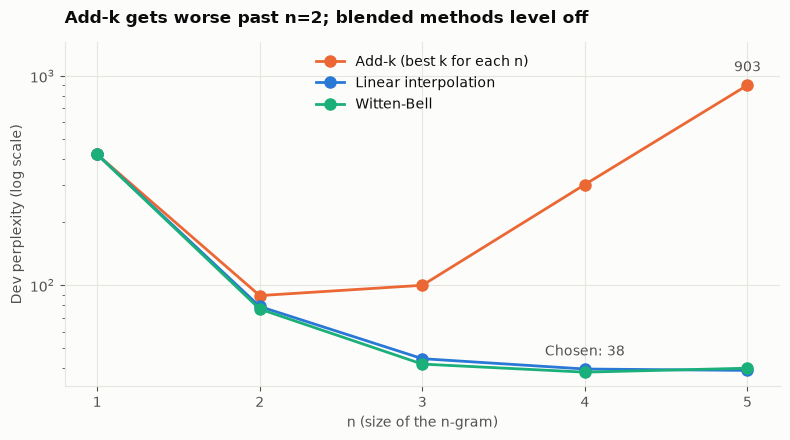

In [8]:
SERIES_3 = "#1baf7a"
best_add_k = results[results.method == "add_k"].groupby("n").dev_perplexity.min()
by_method = results.set_index("n").groupby("method").dev_perplexity
lines = [
    (best_add_k, SERIES_2, "Add-k (best k for each n)"),
    (by_method.get_group("interpolation"), SERIES_1, "Linear interpolation"),
    (by_method.get_group("witten_bell"), SERIES_3, "Witten-Bell"),
]

fig, ax = plt.subplots(figsize=(8, 4.5))
for values, color, label in lines:
    ax.plot(values.index, values.values, marker="o", color=color, label=label)
ax.annotate(f"{best_add_k.iloc[-1]:,.0f}", (MAX_N, best_add_k.iloc[-1]), xytext=(0, 10),
            textcoords="offset points", ha="center", color=MUTED)
ax.annotate(f"Chosen: {best.dev_perplexity:.0f}", (best.n, best.dev_perplexity), xytext=(0, 12),
            textcoords="offset points", ha="center", color=MUTED)
ax.set_yscale("log")
ax.set_ylim(top=best_add_k.max() * 1.6)
ax.set_xticks(range(1, MAX_N + 1))
ax.set_xlabel("n (size of the n-gram)")
ax.set_ylabel("Dev perplexity (log scale)")
ax.set_title(f"Add-k gets worse past n={best_add_k.idxmin()}; blended methods level off", pad=14)
ax.legend(frameon=False, loc="upper center")
fig.tight_layout()
fig.savefig(REPORT_DIR / "dev_perplexity_by_n.png", dpi=150)
plt.show()

## 6. Learning curve: does more data help?

This retrains the chosen setup on growing slices of the train set and shows how much a bigger dataset would help. All runs share one vocabulary, so their scores are comparable.

,train_docs,train_tokens,dev_perplexity
0,25,101274,159.1
1,50,237918,110.6
2,100,518614,83.1
3,150,805430,70.4
4,300,1635186,57.0
5,600,3346183,44.1
6,1000,5512528,38.4


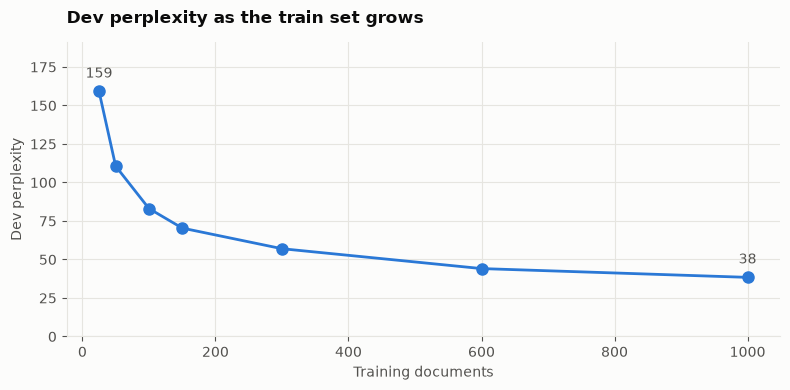

In [9]:
curve = []
for size in [s for s in LEARNING_CURVE_SIZES if s <= TRAIN_DOCS]:
    subset = NGramModel(vocab, model.n).fit(flatten(train_tok[:size]))
    C, T, Y = count_matrices(subset, dev_sentences)
    if model.method == "interpolation":
        P = order_probs(C, T, V)
        dev_score = perplexity(P @ em_lambdas(P))
    elif model.method == "witten_bell":
        dev_score = perplexity(witten_bell_probs(C, T, Y, model.n, V))
    else:
        dev_score = perplexity(add_k_probs(C, T, model.n, model.k, V))
    curve.append({"train_docs": size, "train_tokens": sum(map(len, flatten(train_tok[:size]))),
                  "dev_perplexity": round(dev_score, 1)})
curve = pd.DataFrame(curve)
display(curve)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(curve.train_docs, curve.dev_perplexity, marker="o", color=SERIES_1)
for _, row in curve.iloc[[0, -1]].iterrows():
    ax.annotate(f"{row.dev_perplexity:.0f}", (row.train_docs, row.dev_perplexity), xytext=(0, 10),
                textcoords="offset points", ha="center", color=MUTED)
ax.set_ylim(0, curve.dev_perplexity.max() * 1.2)
ax.set_xlabel("Training documents")
ax.set_ylabel("Dev perplexity")
ax.set_title("Dev perplexity as the train set grows", pad=14)
fig.tight_layout()
fig.savefig(REPORT_DIR / "learning_curve.png", dpi=150)
plt.show()

## 7. Choosing the starting prefix

**What drafting guides say:** contracts usually open with a preamble naming the parties and date ("This Agreement is made as of..."), then recitals beginning "Whereas", then a "Now, therefore" bridge into the terms. Sources: [Sirion on recitals](https://www.sirion.ai/library/contracts/recitals-in-contract/), [Law Insider on preambles](https://www.lawinsider.com/clause/preambles), [PandaDoc on recitals](https://www.pandadoc.com/blog/contract-recitals/).

**What the data says:** the check below measures three things for each candidate, using train only.

- **Opening coverage:** how many documents start a sentence with this phrase in their first few sentences. A narrow window matters, because "Whereas" and "Now, therefore" come after the opening.
- **Median position:** which sentence the phrase usually first appears in. Lower means closer to the true start of the document.
- **Next-word entropy:** how varied the next word is, measured in bits. Too low and every output is the same; too high and the prefix gives little direction.

**The rule:** the prefix must have at least two tokens, usually appear within the first few sentences, and have enough variety in its next word. Among those that qualify, the one with the highest opening coverage wins.

In [10]:
def find_prefix_stats(prefix):
    tokens = tokenize(prefix)
    size = len(tokens)
    opening_docs = sum(any(s[:size] == tokens for s in doc[:OPENING_SENTS]) for doc in train_tok)
    positions = [next(i for i, s in enumerate(doc) if s[:size] == tokens) + 1
                 for doc in train_tok if any(s[:size] == tokens for s in doc)]
    next_words = Counter(
        s[size] if len(s) > size else EOS
        for s in flatten(train_tok) if s[:size] == tokens
    )
    total = sum(next_words.values())
    entropy = -sum(c / total * math.log2(c / total) for c in next_words.values()) if total else 0.0
    return {
        "prefix": prefix, "opening_coverage": f"{opening_docs / len(train_tok):.0%}", "coverage": opening_docs / len(train_tok),
        "median_position": float(np.median(positions)) if positions else None, "sentence_starts": total,
        "distinct_next_words": len(next_words), "next_word_entropy_bits": round(entropy, 2),
        "top_next_words": [word for word, _ in next_words.most_common(4)],
    }


opening_trigrams = Counter()
for doc in train_tok:
    opening_trigrams.update({tuple(s[:3]) for s in doc[:OPENING_SENTS] if len(s) >= 3})
print("Most common sentence openers in the first", OPENING_SENTS, "sentences (share of train docs):")
for gram, docs in opening_trigrams.most_common(10):
    print(f"  {docs / len(train_tok):>5.0%}  {' '.join(gram)}")

prefix_table = pd.DataFrame([find_prefix_stats(p) for p in CANDIDATE_PREFIXES]) \
    .sort_values("coverage", ascending=False).reset_index(drop=True)
display(prefix_table.drop(columns="coverage"))

eligible = prefix_table[
    (prefix_table.prefix.map(lambda p: len(tokenize(p))) >= 2)  # so the model starts with real context
    & (prefix_table.median_position <= OPENING_SENTS)
    & (prefix_table.next_word_entropy_bits >= MIN_PREFIX_ENTROPY)
    & (prefix_table.sentence_starts >= MIN_PREFIX_STARTS)
]
if eligible.empty:
    raise ValueError("No candidate prefix passes the rule. Add candidates or relax the thresholds.")
DEFAULT_PREFIX = eligible.iloc[0].prefix
print(f"Chosen default prefix: '{DEFAULT_PREFIX}'")

Most common sentence openers in the first 5 sentences (share of train docs):
    19%  whereas , the
     9%  now , therefore
     5%  this agreement is
     5%  this employment agreement
     4%  capitalized terms used
     4%  amendment no .
     4%  amended and restated
     4%  a . the
     3%  dated as of
     3%  whereas , pursuant


,prefix,opening_coverage,median_position,sentence_starts,distinct_next_words,next_word_entropy_bits,top_next_words
0,whereas,32%,4.0,1389,17,0.33,"[,, :, the, on]"
1,"whereas , the",19%,4.0,587,112,4.48,"[company, parties, borrower, executive]"
2,this agreement,12%,49.5,2377,63,3.23,"[shall, may, is, and]"
3,"now , therefore",9%,7.0,449,4,0.13,"[,, </s>, the, in]"
4,this amendment,5%,11.0,291,22,3.27,"[shall, may, is, no]"
5,this agreement is made,3%,4.0,61,16,3.47,"[and, the, as, by]"
6,the parties,2%,72.0,760,44,3.71,"[agree, hereto, acknowledge, shall]"
7,this agreement is entered into,1%,15.0,23,7,2.10,"[as, in, under, and]"
8,this agreement is made and entered into,0%,75.0,14,6,2.41,"[for, this, in, as]"
9,in witness whereof,0%,95.0,790,5,0.29,"[,, the, </s>, this]"


Chosen default prefix: 'whereas , the'


## 8. Generating text

Generation builds the next word's probabilities from the learned model, then samples from them:

- **Top-k** keeps only the k most likely words, cutting off rare nonsense.
- **Temperature** controls risk: below 1 plays safe, above 1 gets more varied.
- `<unk>` is never generated.
- **Formatting rules** remove choices that can't be well formed: a sentence ends only after `.`, `?` or `!` with its quotes and brackets closed, a `)` needs an open `(`, a quote can't be empty or run long, and punctuation can't double up. Output stops at the end of a sentence. These rules only affect generation, not perplexity.

**Partial words work too.** The prefix `intro` isn't a word in the vocabulary, so the last fragment is completed from vocabulary words starting with those letters, such as `introduction`.

In [11]:
NO_SPACE_BEFORE = set(",.;:)?!%]'")
NO_SPACE_AFTER = set("($[")
SENTENCE_ENDERS = set(".?!")
PUNCTUATION = set(",;:.?!")


def detokenize(tokens):
    text, in_quote = "", False
    for token in tokens:
        if token == '"':
            text += (" " if text and not in_quote and text[-1] not in NO_SPACE_AFTER else "") + token
            in_quote = not in_quote
            continue
        joined = not text or token in NO_SPACE_BEFORE or text[-1] in NO_SPACE_AFTER or (in_quote and text[-1] == '"')
        text += token if joined else " " + token
    return text[:1].upper() + text[1:]


def candidate_words(model, history):
    """Every word seen after this history at order 2 or above; falls back to the commonest words."""
    words = set()
    for order in range(2, model.n + 1):
        words.update(model.tables[order].get(tuple(history[-(order - 1):]), {}))
    if not words:
        words = sorted(model.tables[1][()], key=model.tables[1][()].get, reverse=True)[:TOP_K]
    return [word for word in words if word != UNK]


def is_allowed(word, sentence):
    """Rule out next words that would make the sentence malformed."""
    last = sentence[-1] if sentence else None
    quote_open = sentence.count('"') % 2 == 1
    open_brackets = sentence.count("(") - sentence.count(")")
    if word == EOS:
        final = next((t for t in reversed(sentence) if t not in ('"', ")")), None)
        return (final in SENTENCE_ENDERS and not quote_open and open_brackets == 0
                and len(sentence) >= MIN_SENTENCE_TOKENS)
    if quote_open and last == '"':
        return word[0].isalnum()  # a quote that just opened needs a word
    if quote_open:
        words_in_quote = sentence[::-1].index('"')
        if words_in_quote >= MAX_QUOTE_TOKENS:
            return word == '"'
    if word == ")":
        return open_brackets > 0 and last != "("
    if word in PUNCTUATION:
        return last is not None and last not in PUNCTUATION and last != "("
    return True


def sample_next(model, history, rng, temperature, top_k, words=None, sentence=None):
    words = list(words) if words is not None else candidate_words(model, history)
    if sentence is not None:
        unigrams = model.tables[1][()]
        words = ([w for w in words if is_allowed(w, sentence)]
                 or [w for w in sorted(unigrams, key=unigrams.get, reverse=True)[:TOP_K]
                     if w != UNK and is_allowed(w, sentence)])
    probs = np.array([model.word_prob(word, history) for word in words])
    keep = np.argsort(probs)[::-1][:top_k]
    probs = probs[keep] ** (1 / temperature)
    return words[keep[rng.choice(len(keep), p=probs / probs.sum())]]


def generate(prefix, model=None, max_tokens=MAX_GEN_TOKENS, temperature=TEMPERATURE, top_k=TOP_K, seed=None):
    """Continue a prefix. Returns (generated text, tokens per sentence)."""
    model = model or globals()["model"]
    rng = np.random.default_rng(seed)
    tokens = tokenize(prefix)

    # A last token outside the vocabulary is treated as a partial word to complete
    fragment = None
    if tokens and tokens[-1] not in model.vocab and tokens[-1].isalpha() and not prefix[-1:].isspace():
        fragment = tokens.pop()

    padding = [BOS] * (model.n - 1)
    current = list(tokens)
    history = padding + [word if word in model.vocab else UNK for word in tokens]

    if fragment:
        matches = [word for word in model.vocab if word.startswith(fragment) and word not in (UNK, EOS)]
        if matches:
            word = sample_next(model, history, rng, temperature, top_k, words=matches)
            current.append(word)
            history.append(word)
        else:
            current.append(fragment)
            history.append(UNK)

    sentences, produced = [], len(current)
    while produced < max_tokens or (current and produced < max_tokens + MAX_SENTENCE_OVERRUN):
        word = sample_next(model, history, rng, temperature, top_k, sentence=current)
        if word == EOS:
            sentences.append(current)
            current, history = [], list(padding)
            continue
        current.append(word)
        history.append(word)
        produced += 1
    # Drop an unfinished last sentence, unless it's all there is
    if current and not sentences:
        sentences.append(current)
    return " ".join(detokenize(sentence) for sentence in sentences), sentences


for seed in range(3):
    text, _ = generate(DEFAULT_PREFIX, seed=SEED + seed)
    print(f"--- Sample {seed + 1} ---\n{text}\n")

--- Sample 1 ---
Whereas, the executive shall continue to be performed in that state, without prejudice, or if the company is unable to determine the principal of the obligations, or any part thereof that is not a party to the other party in any action or inaction under or in connection with the transactions contemplated by this agreement, or any other applicable state or local laws, ordinances, rules, regulations, codes, ordinances, regulations and laws.



--- Sample 2 ---
Whereas, the parties hereto have executed this agreement, the parties hereto (it being understood that the foregoing amounts shall be deposited or transmitted by an instrument in writing signed by the parties hereto. 16. assignment. (m) of the code), the date of termination. In the event that the excise tax and, therefore, in consideration of the payment or performance of any action to be and constitute presumptive evidence of the fact that he has read and understood all of the terms of this agreement nor any of its obligations under section 4.7. (a) no event of default shall have occurred, terminate this agreement; (b).



--- Sample 3 ---
Whereas, the company shall be relieved of the responsibility to inform its affiliates. Article 5. consideration period. (iii) a willful act or omission was in the best interest of the company which, in the sole discretion of ssi.



In [12]:
for prefix in ["whereas", "in witness whereof", "the company shall", "intro", "term"]:
    text, _ = generate(prefix, seed=SEED, max_tokens=50)
    print(f"[{prefix}]\n{text}\n")

[whereas]
Whereas, the board shall be binding upon and inure to the benefit of, and the rules and regulations. The grantor agrees to pay the executive a lump-sum cash payment to the executive under this agreement, including the initial payment (the "plan"), and the borrower or the financial condition of the company.



[in witness whereof]
In witness whereof, the undersigned has caused this note to be executed and delivered by its duly authorized officers as of the closing date the executive notifies the company whether there will be paid in accordance with the terms of this agreement. If the participant to a cash amount equal to the total net profit received by such holder of record of the arbitration hearing, but prior to the date of grant.



[the company shall]
The company shall continue to make available to rsm for review before disposal takes place. The company and the investor shall, severally but not jointly, to purchase the company's interest is insuring the executive's life. (i) is entered into effective as of the date of termination, except as may be necessary or appropriate to comply with any other indemnifying party similarly notified, to assume the defense of such action or proceeding shall be instituted against such person in respect of any of the foregoing and of the company.



[intro]
Introduction. e. o. box 777 medina, oh 43215 - 3418 attention: steven r. hufft any of them and exchange, rights to subscribe for the year in which the company is a party, and has carefully read this amendment and the performance of the executive's duties hereunder or her fiduciary duty to the corporation.



[term]
Term: subject to the terms, covenants, and conditions of any applicable transfer taxes, if any, who controls the purchasers of such securities by the company of its belief that the action or proceeding brought by the company without cause (as defined in the ucc. (a). c. § 651 et seq.), and all of the company's common stock, $0.0001 par value per share of common stock issued or guaranteed by the united states and any other applicable equitable or injunctive relief, and to the commission] or more intermediaries, controls or is controlled



## 9. Is it writing, or copying?

Perplexity can't reveal one common n-gram problem: with a large n, the model may recite its training documents. This measures the longest run of generated words that appears word for word in the train set.

In [13]:
train_text = " " + " ".join(
    word for sentence in apply_vocab(flatten(train_tok), vocab) for word in sentence + [EOS]
) + " "


def longest_copied_run(tokens):
    best, start = 0, 0
    for end in range(1, len(tokens) + 1):
        while start < end and f" {' '.join(tokens[start:end])} " not in train_text:
            start += 1
        best = max(best, end - start)
    return best


def copy_stats(prefix, seeds=10):
    rows = []
    for seed in range(seeds):
        _, sentences = generate(prefix, seed=SEED + seed)
        length = sum(map(len, sentences))
        run = max(longest_copied_run(s) for s in sentences)
        rows.append({"tokens": length, "longest_copied_run": run})
    return pd.DataFrame(rows)


copying = copy_stats(DEFAULT_PREFIX)
print(f"Longest copied run across 10 samples: median {copying.longest_copied_run.median():.0f} words, "
      f"max {copying.longest_copied_run.max()} words (samples are about {copying.tokens.mean():.0f} words long)")

Longest copied run across 10 samples: median 11 words, max 22 words (samples are about 125 words long)


## 10. Final test score

The test set hasn't influenced any decision so far, so this is the fair estimate of performance. It runs once, after tuning is finished.

In [14]:
def score(sentences):
    C, T, Y = count_matrices(model, sentences)
    if model.method == "interpolation":
        return perplexity(order_probs(C, T, V)[:, :model.n] @ model.lambdas)
    if model.method == "witten_bell":
        return perplexity(witten_bell_probs(C, T, Y, model.n, V))
    return perplexity(add_k_probs(C, T, model.n, model.k, V))


# word_prob (used for generation) must agree with the scoring code and sum to 1
sample = apply_vocab(dev_sentences[:50], vocab)
log_prob, steps = 0.0, 0
for sentence in sample:
    history = [BOS] * (MAX_N - 1)
    for word in sentence + [EOS]:
        log_prob += math.log(model.word_prob(word, history))
        steps += 1
        history.append(word)
assert math.isclose(math.exp(-log_prob / steps), score(dev_sentences[:50]), rel_tol=1e-9)
history = [BOS] * (MAX_N - 3) + ["this", "agreement"]
assert math.isclose(sum(model.word_prob(word, history) for word in vocab), 1.0, rel_tol=1e-9)

final_scores = {
    "train_perplexity": score(flatten(train_tok)),
    "dev_perplexity": score(dev_sentences),
    "test_perplexity": score(flatten(test_tok)),
}
display(pd.Series(final_scores, name="perplexity").round(1).to_frame())

,perplexity
train_perplexity,5.0
dev_perplexity,38.4
test_perplexity,33.9


## 11. Save and reload

This saves the model and its results, then reloads it to confirm the saved version works.

In [15]:
def save_model(model, path):
    # Only the orders in use are needed for generation
    payload = {
        "vocab": model.vocab, "max_n": model.max_n, "n": model.n, "method": model.method,
        "lambdas": model.lambdas, "k": model.k,
        "tables": {order: model.tables[order] for order in range(1, model.n + 1)},
        "totals": {order: model.totals[order] for order in range(1, model.n + 1)},
    }
    with path.open("wb") as f:
        pickle.dump(payload, f, protocol=pickle.HIGHEST_PROTOCOL)


def load_model(path):
    with path.open("rb") as f:
        payload = pickle.load(f)
    loaded = NGramModel(payload["vocab"], payload["max_n"])
    for field in ("n", "method", "lambdas", "k", "tables", "totals"):
        setattr(loaded, field, payload[field])
    return loaded


save_model(model, MODEL_PATH)
reloaded = load_model(MODEL_PATH)
assert generate(DEFAULT_PREFIX, model=reloaded, seed=SEED)[0] == generate(DEFAULT_PREFIX, seed=SEED)[0]

metrics = {
    "config": {"train_docs": TRAIN_DOCS, "dev_docs": DEV_DOCS, "test_docs": TEST_DOCS, "min_count": MIN_COUNT},
    "vocab_size": V, "n": model.n, "method": model.method,
    "lambdas": None if model.lambdas is None else [round(float(w), 4) for w in model.lambdas],
    "k": None if model.k is None or pd.isna(model.k) else float(model.k),
    "default_prefix": DEFAULT_PREFIX,
    **{name: round(value, 2) for name, value in final_scores.items()},
    "median_longest_copied_run": float(copying.longest_copied_run.median()),
}
(REPORT_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2))
print(f"Saved {MODEL_PATH.name} ({MODEL_PATH.stat().st_size / 1e6:.0f} MB); reload check passed")
print(json.dumps(metrics, indent=2))

Saved ngram_model.pkl (85 MB); reload check passed
{
  "config": {
    "train_docs": 1000,
    "dev_docs": 100,
    "test_docs": 100,
    "min_count": 2
  },
  "vocab_size": 22618,
  "n": 4,
  "method": "witten_bell",
  "lambdas": null,
  "k": null,
  "default_prefix": "whereas , the",
  "train_perplexity": 4.97,
  "dev_perplexity": 38.39,
  "test_perplexity": 33.9,
  "median_longest_copied_run": 11.0
}


## 12. Try your own prefix

Change the prefix and re-run this cell. Full words and partial words both work.

In [16]:
print(generate("this agreement is made", seed=7)[0])

This agreement is made the initial purchasers, as the case may be, and the company. "net receipts" code "means the securities exchange act of" material adverse effect.
